# 03 · Model zoo, strata and graph features

Question: does anything beat **followers + engagement** for predicting views (TikTok, YouTube, X)? Same target (log10 views) and validation as notebook 01: 5-fold CV grouped by brand, MAE with a brand-cluster bootstrap CI.
1. Many standard models on the same features.
2. Graph features: author-mention graph and a text-similarity graph.
3. Where does the error concentrate (strata, incl. our AI labels)?

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "reach_samples_students.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
import eda_utils as eu, modeling as mo, extra_models as em

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200, "display.max_columns", 30)

In [2]:
f, meta = em.load(ROOT)
meta.assign(text=meta.text.str[:60]).head()

,platform,brand,b24_estimated_reach,author_followers,y,author,text
5,twitter,Citizens Bank,24.0,247.0,1.995635,UARreVAMP,"@rukky_nate Savanna Bank, All States Bank, Ape..."
6,twitter,Citizens Bank,0.0,0.0,0.000000,SportsVacay,2026 MLB All-Star Week in Philadelphia - July ...
7,twitter,Citizens Bank,121.0,1218.0,1.857332,Mr_Iyantan,"In the space of 30 years, we have had: Interco..."
8,twitter,Citizens Bank,7800.0,1061.0,2.636488,ijeoma_miriam,@rukky_nate @EzeasorIje In the space of 30 yea...
11,twitter,Aldi,700.0,1244.0,2.170262,used2shopataldi,"aldi, huh? i used to shop there..."


In [3]:
f.head()

,log_followers,log_likes,na_likes,log_comments,na_comments,log_shares,na_shares,na_followers,english,text_len,type_code,sentiment_code,month,metrics_age_days
5,2.392697,0.000000,0,NaN,1,0.000000,0,0,1,2.240549,0,0,24317,57
6,NaN,0.000000,0,NaN,1,0.000000,0,0,1,2.612784,1,0,24317,57
7,3.085647,0.000000,0,NaN,1,0.000000,0,0,1,2.440909,0,0,24317,57
8,3.025715,2.995732,0,1.609438,0,1.386294,0,0,1,2.477121,0,0,24317,57
11,3.094820,0.693147,0,NaN,1,0.000000,0,0,1,1.544068,0,0,24318,50


## 1 · Model zoo on followers + engagement
Ridge, kNN, random forest, extra trees, boosting (squared and median loss) and a simple blend.

In [4]:
zres, zpred = [], {}
for p in mo.PLATS:
    r, pr = em.zoo(f, meta, p); zres.append(r); zpred[p] = pr
zoo = pd.concat(zres, ignore_index=True)
zoo.pivot(index="model", columns="platform", values="MAE").round(3)

platform,TikTok,X (Twitter),YouTube
model,,,
blend (ridge+forest+boosting),0.278,0.483,0.467
extra trees,0.277,0.481,0.455
gradient boosting,0.291,0.496,0.469
"gradient boosting, median loss",0.282,0.484,0.451
kNN (k=25),0.287,0.532,0.491
random forest,0.285,0.494,0.471
ridge,0.278,0.487,0.545


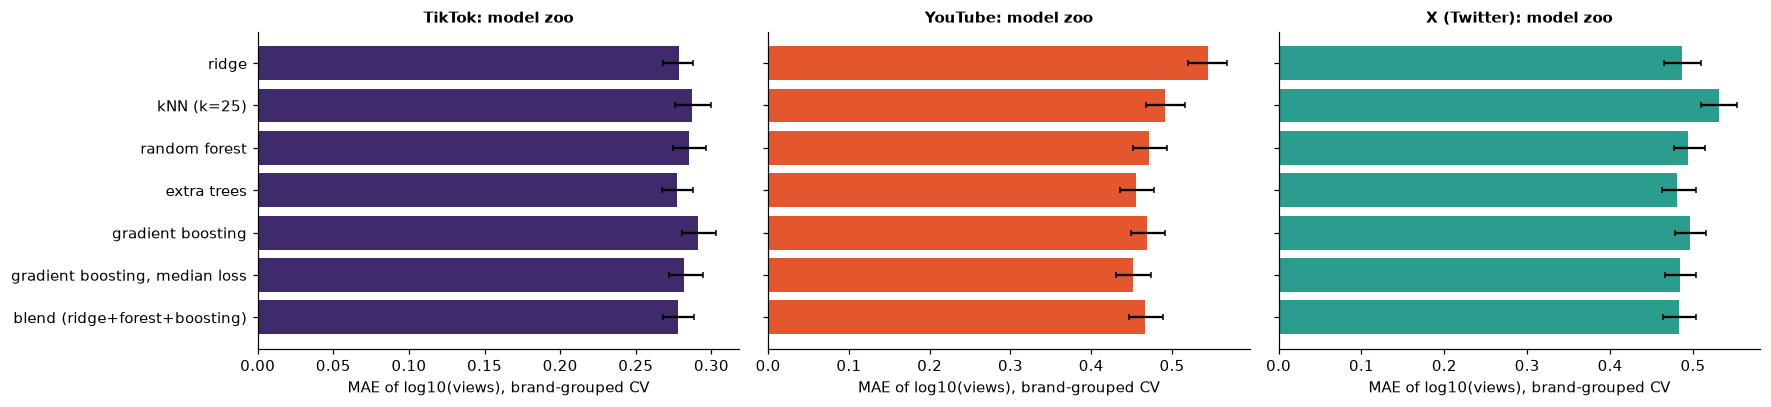

In [5]:
em.plot_bars(zoo, 'model zoo')

Takeaway: all models land within the CI of each other. The signal is in likes and comments, not in the learner.

## 2 · Graph features
Two graphs per platform:
- **author graph:** mentions linked by the same author; feature = smoothed mean views of the author's other mentions in the training fold.
- **text graph:** kNN on TF-IDF cosine similarity; features = mean views of the 10 nearest training mentions, and label-free smoothing of likes / comments / followers over neighbours (SGC style, 2 hops).

Target-based features use the training fold only, the row itself is left out.

In [6]:
gres = []; gpred = {}
for p in mo.PLATS:
    r, pr = em.graph_ladder(f, meta, p); gres.append(r); gpred[p] = pr
graph = pd.concat(gres, ignore_index=True)
graph.pivot(index="model", columns="platform", values="MAE").reindex(graph.model.unique()).round(3)

platform,TikTok,X (Twitter),YouTube
model,,,
engagement only,0.291,0.496,0.469
+ degree (author / brand mention counts),0.293,0.505,0.467
+ label-free smoothing over text graph,0.292,0.490,0.471
+ author target mean,0.290,0.496,0.460
+ text-neighbour target mean,0.293,0.504,0.475
+ all graph features,0.290,0.498,0.464


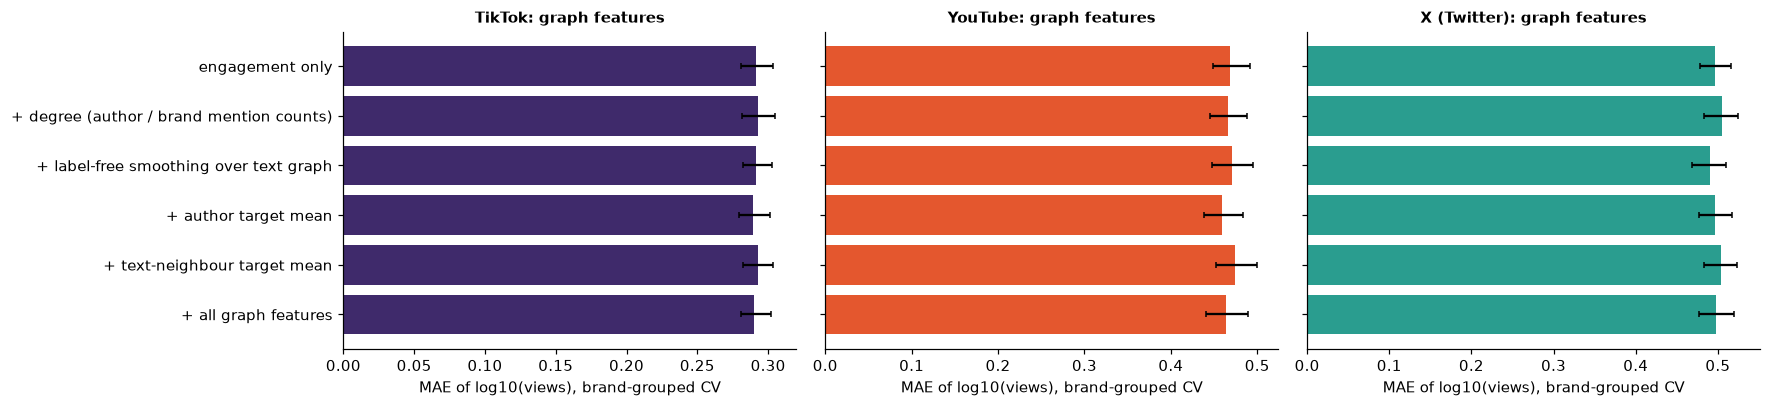

In [7]:
em.plot_bars(graph, 'graph features')

In [8]:
reps = {eu.NAMES[p]: (lambda d: round(float((d.author_mentions > 1).mean()), 3))(em.author_degree(meta[meta.platform == p].reset_index(drop=True)).rpow(10)) for p in mo.PLATS}
pd.Series(reps, name="share of mentions whose author appears more than once").to_frame()

,share of mentions whose author appears more than once
TikTok,0.057
YouTube,0.268
X (Twitter),0.126


Takeaway: graph structure adds nothing measurable. The only visible gain is the author mean on YouTube (27% of mentions share an author), and it sits inside the CI.

## 3 · Strata
Out-of-fold error of the blend, split by our AI labels (type, sentiment), follower tier, engagement tier and language.

In [9]:
lab = pd.read_csv(ROOT / "data" / "processed" / "mention_labels.csv", dtype={"mention_id": str}).set_index("mention_id")
labels = lab.reindex(eu.load(ROOT).astype({"mention_id": str}).loc[meta.index].mention_id).reset_index(drop=True); labels.index = meta.index
BL = "blend (ridge+forest+boosting)"
st = pd.concat([em.strata_table(f, meta, p, zpred[p][BL], labels) for p in mo.PLATS], ignore_index=True)
st.pivot_table(index=["stratifier", "stratum"], columns="platform", values=["MAE", "mentions"]).round(2)

MAE                     mentions                    
platform                               TikTok X (Twitter) YouTube   TikTok X (Twitter) YouTube
stratifier      stratum                                                                       
engagement tier Q1 lowest                0.32        0.47    0.72    623.0       176.0   555.0
                Q2                       0.25        0.45    0.45    623.0       176.0   555.0
                Q3                       0.26        0.46    0.39    622.0       176.0   554.0
                Q4 highest               0.28        0.39    0.30    623.0       176.0   555.0
                missing likes/comments    NaN        0.51    0.50      NaN      1099.0   222.0
followers tier  Q1 smallest              0.27        0.53    0.53    610.0       437.0   607.0
                Q2                       0.26        0.48    0.47    610.0       436.0   607.0
                Q3                       0.26        0.44    0.44    609.0       436.0   607.0
                Q4 largest               0.31        0.49    0.43    610.0       437.0   607.0
                no followers             0.28        0.46    0.41     52.0        57.0    13.0
language        english                  0.28        0.48    0.46   2343.0      1775.0  2367.0
                other                    0.31        0.44    0.57    148.0        28.0    74.0
our sentiment   negative                 0.26        0.48    0.43    108.0       413.0    31.0
                neutral                  0.29        0.48    0.46   1306.0      1083.0  1989.0
                positive                 0.26        0.49    0.50   1077.0       307.0   421.0
our type label  organic                  0.25        0.47    0.44   1179.0      1242.0   734.0
                promo                    0.30        0.48    0.48    844.0       334.0  1037.0
                spam                     0.31        0.56    0.50    331.0       212.0   370.0
                unclear                  0.28        0.45    0.45    137.0        15.0   300.0

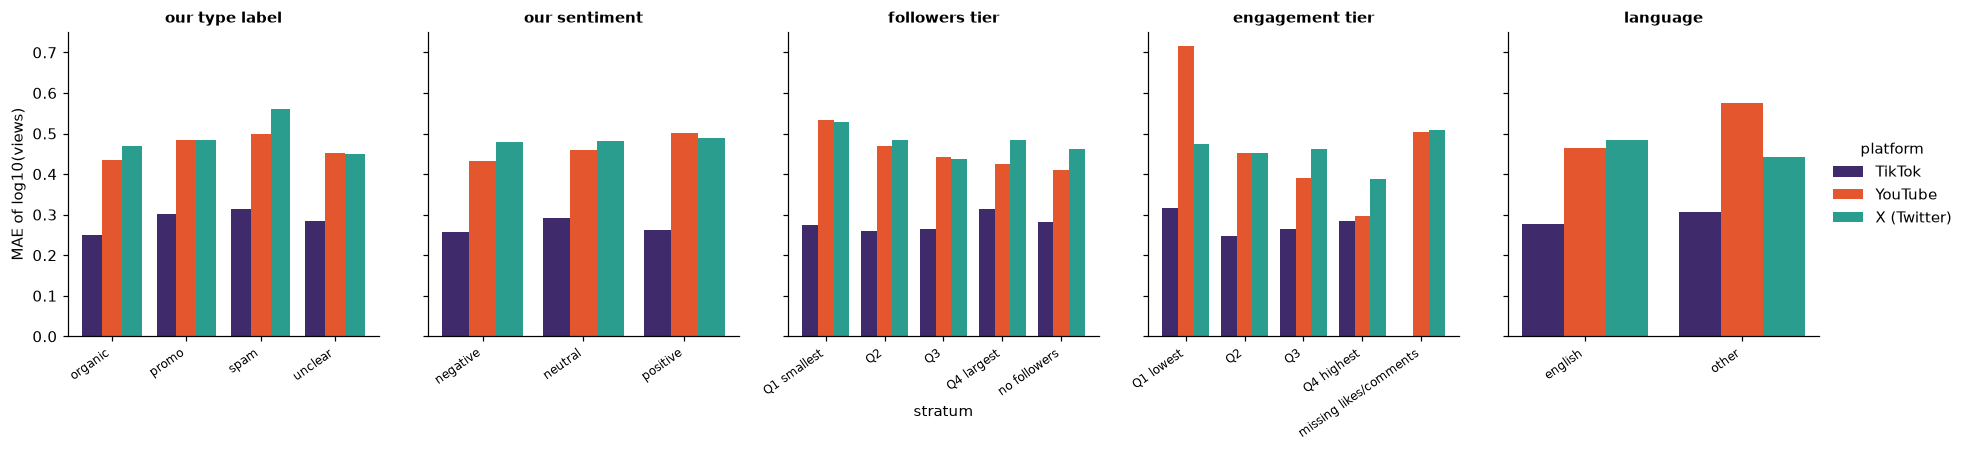

In [10]:
em.plot_strata(st)

In [11]:
bias = st.pivot_table(index=["stratifier", "stratum"], columns="platform", values="bias").round(2)
bias

platform                                TikTok  X (Twitter)  YouTube
stratifier      stratum                                             
engagement tier Q1 lowest                -0.00         0.02    -0.07
                Q2                        0.00        -0.01     0.08
                Q3                        0.02        -0.01    -0.00
                Q4 highest               -0.02        -0.00     0.01
                missing likes/comments     NaN        -0.00    -0.03
followers tier  Q1 smallest              -0.00        -0.02    -0.00
                Q2                        0.01         0.00     0.01
                Q3                        0.02         0.02     0.02
                Q4 largest               -0.02        -0.02    -0.02
                no followers             -0.05         0.11    -0.04
language        english                   0.00        -0.00     0.01
                other                    -0.01         0.05    -0.11
our sentiment   negative                 -0.03         0.02     0.03
                neutral                  -0.00        -0.02     0.03
                positive                  0.01         0.03    -0.14
our type label  organic                   0.04         0.02     0.02
                promo                    -0.08        -0.03    -0.04
                spam                      0.03        -0.09    -0.01
                unclear                   0.08         0.25     0.12

Takeaway: error is largest for the **smallest-engagement** posts, and our type labels (organic / promo / spam) change the error very little.

### Stratified models
One model per follower tier vs one pooled model.

In [12]:
sm = pd.concat([em.stratum_models(f, meta, p) for p in mo.PLATS], ignore_index=True)
sm.pivot(index="model", columns="platform", values="MAE").round(3)

platform,TikTok,X (Twitter),YouTube
model,,,
one model per follower tier,0.311,0.509,0.491
one pooled model,0.291,0.496,0.469


Takeaway: splitting the data only removes training rows; the pooled model is as good or better.

## 5 · Our labels and views
Do promotional and spam mentions get different views than organic ones, and does that survive controlling for engagement? Residual = log10(views) minus the out-of-fold blend prediction; CI by brand-cluster bootstrap. Both language versions are saved for the slides.

In [13]:
ls = em.labels_summary(meta, labels, {p: zpred[p][BL] for p in mo.PLATS})
ls.round(2)

,platform,type,n,median,median lo,median hi,resid,resid lo,resid hi
0,TikTok,organic,1179,2.89,2.86,2.93,-0.04,-0.06,-0.02
1,TikTok,promo,844,2.86,2.80,2.94,0.08,0.04,0.11
2,TikTok,spam,331,2.78,2.63,2.86,-0.03,-0.09,0.02
3,YouTube,organic,734,2.60,2.48,2.69,-0.02,-0.06,0.03
4,YouTube,promo,1037,2.78,2.66,2.92,0.04,-0.01,0.09
5,YouTube,spam,370,2.59,2.41,2.83,0.01,-0.08,0.10
6,X (Twitter),organic,1242,1.41,1.34,1.46,-0.02,-0.06,0.02
7,X (Twitter),promo,334,1.68,1.46,1.83,0.03,-0.04,0.11
8,X (Twitter),spam,212,1.46,1.16,1.69,0.09,-0.03,0.20


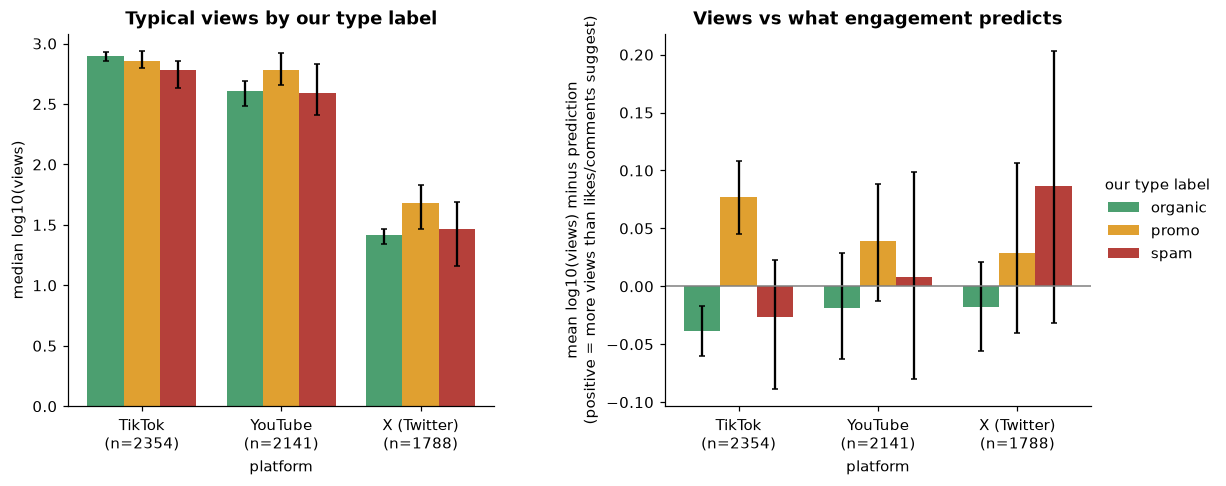

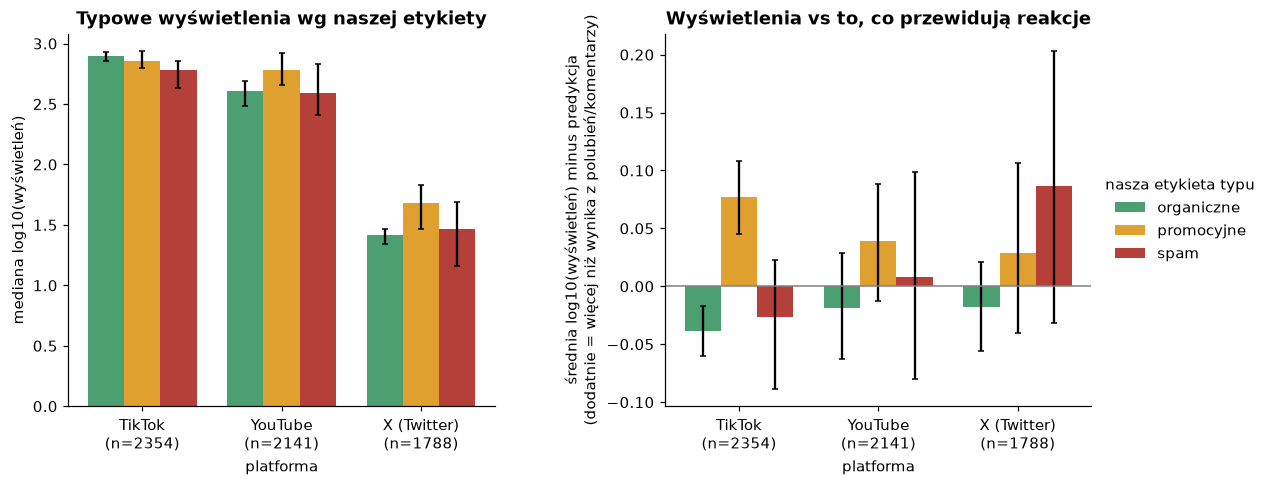

In [14]:
em.labels_figure(ls, 'en', ROOT / 'figures' / 'zoo_labels_en.png')
em.labels_figure(ls, 'pl', ROOT / 'figures' / 'zoo_labels_pl.png')

## 4 · Summary

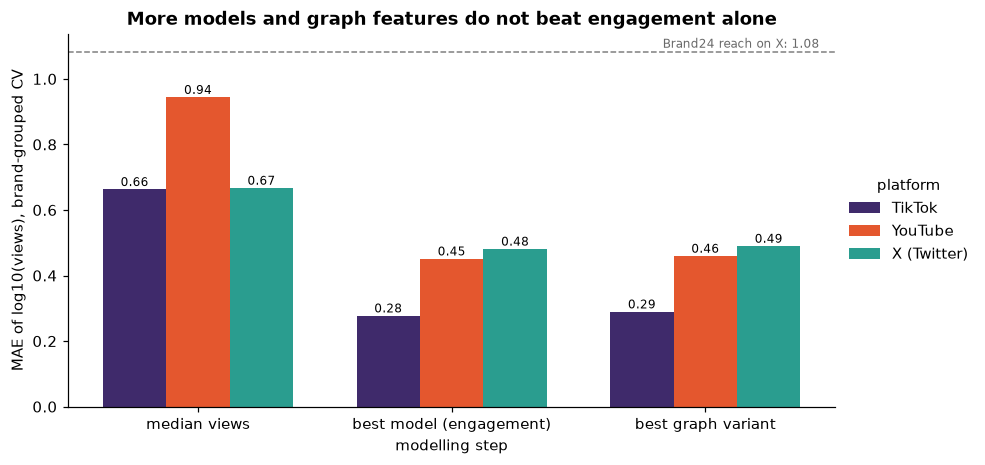

In [15]:
med = {p: zoo[(zoo.platform == eu.NAMES[p])].MAE.max() for p in mo.PLATS}   # placeholder replaced below
res = json.load(open(ROOT / "data" / "processed" / "results_numbers.json"))["ladder"]
med = {p: res[p]["median views"][0] for p in mo.PLATS}
b24 = res["twitter"]["Brand24 reach as-is"][0]
em.summary_figure(zoo, graph, med, b24, ROOT / "figures" / "zoo_summary_en.png")

In [16]:
best = pd.DataFrame({"median views": pd.Series(med).rename(eu.NAMES),
                     "best zoo model": zoo.groupby("platform").MAE.min(),
                     "best graph variant": graph.groupby("platform").MAE.min()}).round(3)
best

,median views,best zoo model,best graph variant
TikTok,0.663,0.277,0.29
X (Twitter),0.667,0.481,0.49
YouTube,0.944,0.451,0.46


Numbers for the slides (`pitchdeck/results_build.py`).

In [17]:
out = {"summary": {}, "labels": ls.to_dict("records"), "strata": st.to_dict("records")}
for p in mo.PLATS:
    n = eu.NAMES[p]; z = zoo[zoo.platform == n].sort_values("MAE").iloc[0]; g = graph[graph.platform == n].sort_values("MAE").iloc[0]
    base = graph[(graph.platform == n) & (graph.model == "engagement only")].MAE.iloc[0]
    out["summary"][p] = {"median": med[p], "zoo_best": float(z.MAE), "zoo_best_model": z.model, "graph_best": float(g.MAE), "graph_best_variant": g.model, "engagement_only": float(base), "n_models": int((zoo.platform == n).sum())}
json.dump(out, open(ROOT / "data" / "processed" / "zoo_numbers.json", "w"), indent=1, default=float)
pd.DataFrame(out["summary"]).T.round(3)

,median,zoo_best,zoo_best_model,graph_best,graph_best_variant,engagement_only,n_models
tiktok,0.663,0.277326,extra trees,0.289544,+ author target mean,0.291277,7
youtube,0.944,0.451132,"gradient boosting, median loss",0.459507,+ author target mean,0.468778,7
twitter,0.667,0.481175,extra trees,0.48987,+ label-free smoothing over text graph,0.496357,7
